In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
sns.set_theme(style="whitegrid")

c = pd.read_csv("../data/processed/manali_daily.csv", index_col="Date", parse_dates=True)
POLL = ["PM2.5", "NO", "NO2", "NOx", "NH3", "CO", "SO2"]
print(c.shape, c.index.min().date(), "to", c.index.max().date())
print("Left-over missing values:\n", c[["AQI"] + POLL].isna().sum().to_string())

print("\nLongest run of identical consecutive values (stuck sensor check):")
for p in ["AQI"] + POLL:
    s = c[p]
    run = (s != s.shift()).cumsum()
    print(f"  {p}: {int(s.groupby(run).transform('size').max())} days")

print("\nFive highest CO readings:")
print(c["CO"].nlargest(5).round(1).to_string())

(601, 10) 2017-09-28 to 2019-05-21
Left-over missing values:
 AQI       0
PM2.5     5
NO        5
NO2       5
NOx      11
NH3       5
CO        5
SO2       5

Longest run of identical consecutive values (stuck sensor check):
  AQI: 3 days
  PM2.5: 1 days
  NO: 2 days
  NO2: 2 days
  NOx: 2 days
  NH3: 1 days
  CO: 32 days
  SO2: 1 days

Five highest CO readings:
Date
2017-10-12    40.2
2017-10-13    39.8
2017-10-11    27.7
2017-10-10    15.2
2018-05-01     5.0


In [2]:
c[["AQI"] + POLL] = c[["AQI"] + POLL].ffill(limit=3).bfill(limit=3)
print("Missing after edge fill:", int(c[["AQI"] + POLL].isna().sum().sum()))

Missing after edge fill: 17


AQI
Good              6
Satisfactory    324
Moderate        193
Poor             62
Very Poor        15
Severe            1
Beyond            0


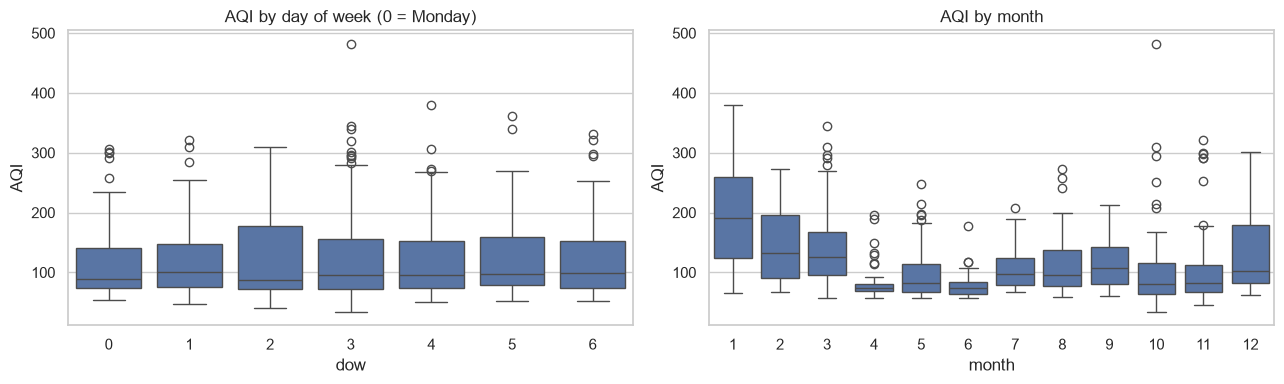

In [8]:
cats = pd.cut(c["AQI"], [0, 50, 100, 200, 300, 400, 500, 1000],
              labels=["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe", "Beyond"])
print(cats.value_counts().sort_index().to_string())

c["dow"] = c.index.day_of_week; c["month"] = c.index.month
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=c, x="dow", y="AQI", ax=ax[0]); ax[0].set_title("AQI by day of week (0 = Monday)")
sns.boxplot(data=c, x="month", y="AQI", ax=ax[1]); ax[1].set_title("AQI by month")
plt.tight_layout(); plt.savefig("../figures/03_patterns.png", dpi=150); plt.show()

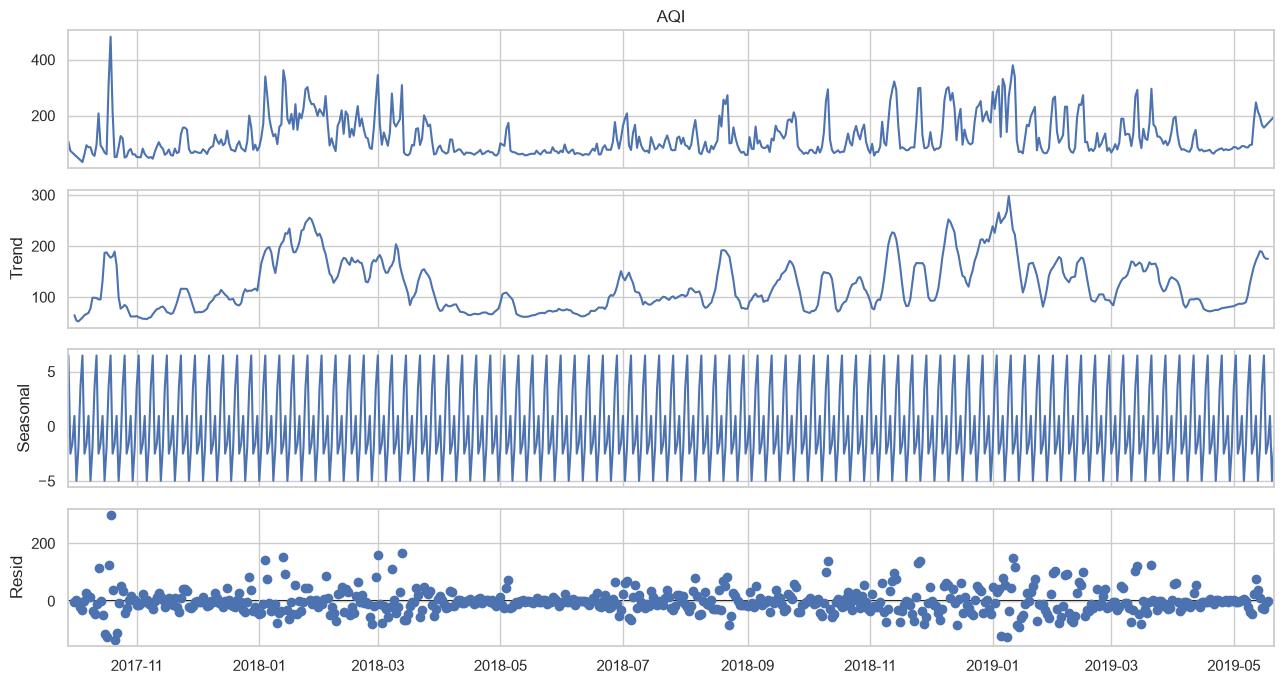

In [4]:
dec = seasonal_decompose(c["AQI"], model="additive", period=7)
fig = dec.plot(); fig.set_size_inches(13, 7)
plt.tight_layout(); plt.savefig("../figures/03_decomposition.png", dpi=150); plt.show()

In [14]:
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning

def stationarity(s, name):
    s = s.dropna()
    adf_p = adfuller(s, autolag="AIC", result_object=False)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(s, regression="c", nlags="auto", store=False, result_object=False)[1]
    print(f"{name:22s} ADF p = {adf_p:.4f} | KPSS p = {kpss_p:.4f} (KPSS p is capped at 0.1)")

stationarity(c["AQI"], "AQI")
stationarity(c["AQI"].diff(), "AQI, differenced once")

AQI                    ADF p = 0.0002 | KPSS p = 0.1000 (KPSS p is capped at 0.1)
AQI, differenced once  ADF p = 0.0000 | KPSS p = 0.1000 (KPSS p is capped at 0.1)


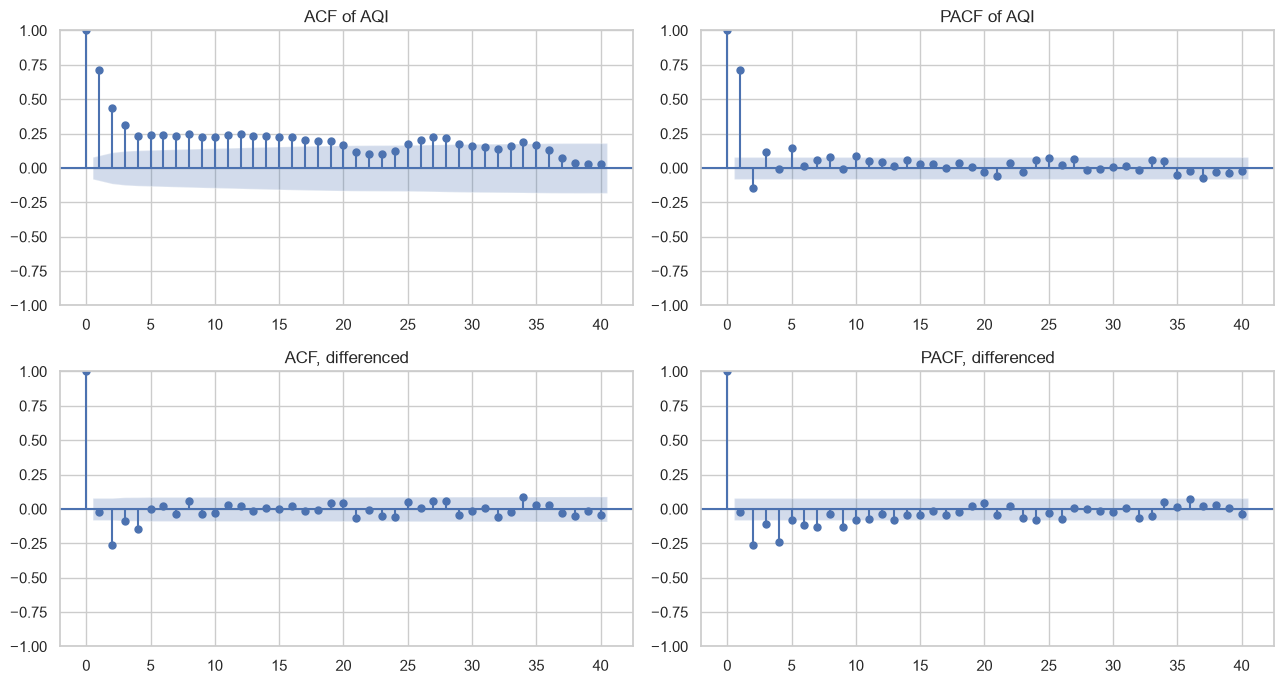

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(c["AQI"], lags=40, ax=ax[0, 0], title="ACF of AQI")
plot_pacf(c["AQI"], lags=40, ax=ax[0, 1], title="PACF of AQI", method="ywm")
plot_acf(c["AQI"].diff().dropna(), lags=40, ax=ax[1, 0], title="ACF, differenced")
plot_pacf(c["AQI"].diff().dropna(), lags=40, ax=ax[1, 1], title="PACF, differenced", method="ywm")
plt.tight_layout(); plt.savefig("../figures/03_acf_pacf.png", dpi=150); plt.show()

train       2017-09-28 to 2018-11-21  420 days  mean AQI 113
validation  2018-11-22 to 2019-02-19  90 days  mean AQI 170
test        2019-02-20 to 2019-05-21  91 days  mean AQI 119


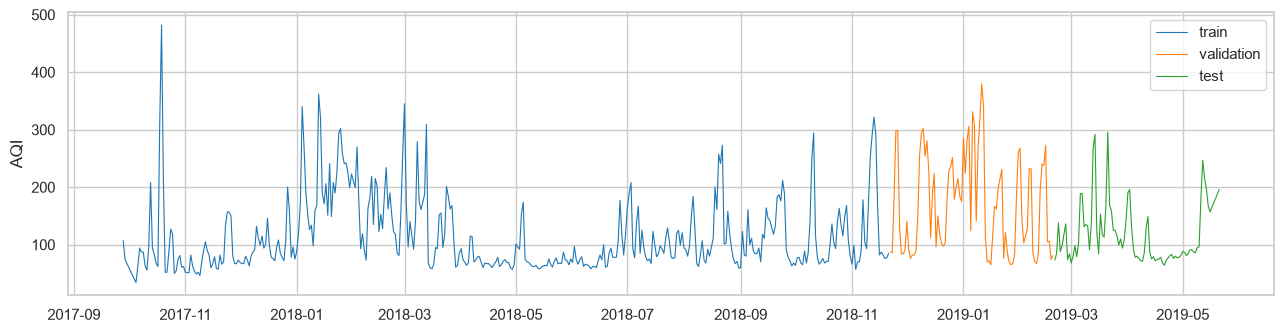

In [11]:
n = len(c); i1, i2 = int(n * 0.70), int(n * 0.85)
parts = {"train": c.iloc[:i1], "validation": c.iloc[i1:i2], "test": c.iloc[i2:]}
for k, v in parts.items():
    print(f"{k:11s} {v.index[0].date()} to {v.index[-1].date()}  {len(v)} days  mean AQI {v['AQI'].mean():.0f}")

plt.figure(figsize=(13, 3.5))
for (k, v), col in zip(parts.items(), ["tab:blue", "tab:orange", "tab:green"]):
    plt.plot(v.index, v["AQI"], lw=0.8, color=col, label=k)
plt.legend(); plt.ylabel("AQI")
plt.tight_layout(); plt.savefig("../figures/03_split.png", dpi=150); plt.show()

In [12]:
# where are the 17 missing values?
still = c[POLL][c[POLL].isna().any(axis=1)]
print("Rows with a missing pollutant:", len(still))
print(still.index.min().date() if len(still) else None, "to", still.index.max().date() if len(still) else None)
print(still.isna().sum().to_string())

# the stuck CO stretch
s = c["CO"]
run = (s != s.shift()).cumsum()
size = s.groupby(run).transform("size")
stuck = c[size == size.max()]
print("\nStuck CO:", stuck.index.min().date(), "to", stuck.index.max().date(), "value =", stuck["CO"].iloc[0])

# the October 2017 spike
print(c.loc["2017-10-08":"2017-10-20", ["AQI", "PM2.5", "NO2", "SO2", "CO"]].round(1).to_string())

Rows with a missing pollutant: 5
2017-09-28 to 2019-05-21
PM2.5    2
NO       2
NO2      2
NOx      5
NH3      2
CO       2
SO2      2

Stuck CO: 2017-12-08 to 2018-01-08 value = 0.0
              AQI  PM2.5   NO2   SO2    CO
Date                                      
2017-10-08   87.0   44.9  12.1  15.0   2.1
2017-10-09   87.0   40.9  12.2  15.2   2.7
2017-10-10   63.0   29.2  16.9   3.2  15.2
2017-10-11   56.0   41.9  22.6   5.1  27.7
2017-10-12   96.0   33.8  22.6   2.5  40.2
2017-10-13  208.0   46.2  28.2   5.2  39.8
2017-10-14   94.0   66.0  26.3   7.6   1.0
2017-10-15   83.0   35.7  23.9  10.2   1.0
2017-10-16   68.0   30.2  24.6  11.2   0.7
2017-10-17   62.0   81.0  20.2   8.1   1.0
2017-10-18  310.0  200.5  26.8  17.7   1.2
2017-10-19  482.0  311.4  26.7  20.0   1.0
2017-10-20  214.0   53.7  25.7   7.6   0.8


In [15]:
c2 = c.loc["2017-10-15":].copy()                      # drop the suspect first days (CO spike)
c2[POLL] = c2[POLL].interpolate(method="linear", limit=5, limit_area="inside")
c2[POLL] = c2[POLL].ffill(limit=2)                    # the last 2 days only: copies yesterday's value
c2["CO_unreliable"] = (c2.index >= "2017-12-08") & (c2.index <= "2018-01-08")   # stuck at 0.0

print("Rows:", len(c2), "|", c2.index.min().date(), "to", c2.index.max().date())
print("Missing values left:", int(c2[["AQI"] + POLL].isna().sum().sum()))
c2.to_csv("../data/processed/manali_model.csv")

Rows: 584 | 2017-10-15 to 2019-05-21
Missing values left: 0
